# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

os.environ["JAX_PLATFORM_NAME"] = "cpu"  # must be set before importing jax

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx

import matplotlib as mpl
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.ticker as mticker
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget
# %matplotlib inline

INFO:2026-05-28 11:02:16,517:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-28 11:02:16,517 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-05-28 11:02:16,696 - INFO - SkewerBundle class definition complete


In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers
import skewerjax.utils.aux as aux
import skewerjax.utils.plotting_tools as pt

import skewerjax.optical_depth.optical_depth as od

from skewerjax.constants.physical_constants import phys

# Cosmology

In [3]:
# Create cosmology object
cosmology = Cosmology(H0=phys.H0, Omega_r_0=0.0, Omega_m_0=1.0, Omega_k_0=0.0, Omega_lambda_0=0.0)
# Define which cosmology to use, this is set as default to 0 since skewer and cosmology objects can deal with multiple cosmologies at once, 
# but other classes such as fields and optical depth are currently only set up for a single cosmology at a time
ii_cosmology = 0

# Lines

In [4]:
line_bundle = sjx.constants.lines.LineBundle(["HI-LyA", "HI-LyA-1206"], ref_line_id = "HI-LyA") # "SiIII-1206", "SiII-1190", "SiII-1193" # "HI-LyA-1206", "HI-LyA-1193", "HI-LyA-1190"

# Skewers

In [5]:
L_box = 200.0  # Mpc
z_box = 2.0

In [6]:
N_grid_skewers = 5
N_ppsk = 5000

points_grid_skewers = aux.make_skewer_grid_points(L_box, N_grid_skewers, N_ppsk, direction="y")
points = jnp.reshape(points_grid_skewers, (N_grid_skewers**2, N_ppsk, 3))

In [7]:
skewer_bundle = SkewerBundle(spatial_points=points, cosmologies=cosmology, a0=1/(1+z_box), x0=L_box)

2026-05-28 11:02:19,776 - INFO - Initializing SkewerBundle with 25 skewers, 5000 points per skewer
2026-05-28 11:02:19,804 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 25 skewers
2026-05-28 11:02:19,814 - INFO - All skewers set to absorption mode
2026-05-28 11:02:19,848 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-05-28 11:02:20,003 - INFO - Computing comoving distances along skewer direction
2026-05-28 11:02:20,117 - INFO - Computing scale factors from cosmology
2026-05-28 11:02:23,111 - INFO - Storing quadri-vectors
2026-05-28 11:02:23,146 - INFO - SkewerBundle initialization complete


# Fields

In [8]:
N_absorvers = 1
Delta = 2.0 * (L_box / N_ppsk)

n0_HI = 5e-10
T0_HI = 1

In [9]:
n0_SiIII = n0_HI
T0_SiIII = T0_HI

n0_SiII = n0_HI
T0_SiII = T0_HI

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-5, C0=T0_HI, L_box=L_box, base_seed=0)),    # UNITS: [K]
        "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-20, C0=n0_HI, L_box=L_box, base_seed=0)), # [cm^-3]
        "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    },
    # "SiIII": {
    #     "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-5, C0=T0_SiIII, L_box=L_box, base_seed=0)),    # UNITS: [K]
    #     "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-20, C0=n0_SiIII, L_box=L_box, base_seed=0)), # [cm^-3]
    #     "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
    #     "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
    #     "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    # },
    # "SiII": {
    #     "temperature": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-5, C0=T0_SiII, L_box=L_box, base_seed=0)),    # UNITS: [K]
    #     "number_density": ScalarField(toy_samplers.periodic_top_hat_absorber_sampler(N_absorvers=N_absorvers, Delta=Delta, C_low=1e-20, C0=n0_SiII, L_box=L_box, base_seed=0)), # [cm^-3]
    #     "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
    #     "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
    #     "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
    # },
})

In [10]:
# T0_HI = 1e5
# T0_Si = 2e6
# n0_min = 1e-16
# n0_max = 1e-10
# def pk_template(k: jnp.ndarray, A, n, k0, k_cut):
#     # P(k) = A (k/k0)^n exp[-(k/k_cut)^2]
#     kk = jnp.maximum(k, 1e-12)
#     return A * (kk / k0) ** n * jnp.exp(-(kk / k_cut) ** 2)
# number_density_sampler = toy_samplers.number_density_sampler_gaussian_3d(
#     key=jax.random.PRNGKey(0),
#     pk_of_k=lambda k: pk_template(k, A=5.0, n=-2.5, k0=2.0, k_cut=50.0),
#     n0_min=n0_min, n0_max=n0_max, L_box=L_box,
#     grid_shape=(256, 256, 256), contrast=1.2,
# )
# fields = Fields({
#     "HI": {
#         "temperature": ScalarField(toy_samplers.temperature_sampler(T0_HI, T0_HI, L_box)),    # UNITS: [K]
#         "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
#         "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
#         "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
#         "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
#     },
#     "SiIII": {
#         "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
#         "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
#         "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
#         "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
#         "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
#     },
#     # "SiII": {
#     #     "temperature": ScalarField(toy_samplers.temperature_sampler(T0_Si, T0_Si, L_box)),    # UNITS: [K]
#     #     "velocity": VectorField(toy_samplers.velocity_sampler(0.0, 0.0, L_box)),        # UNITS: [km/s]
#     #     "number_density": ScalarField(number_density_sampler),                          # [cm^-3]
#     #     "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),         # UNITS: [km/s]
#     #     "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0))        # UNITS: [GHz]
#     # },
# })

### Plot Fields

In [11]:
sampled_fields = fields.sample(skewer_bundle.quadri_vectors[ii_cosmology], skewer_bundle.los_directions)

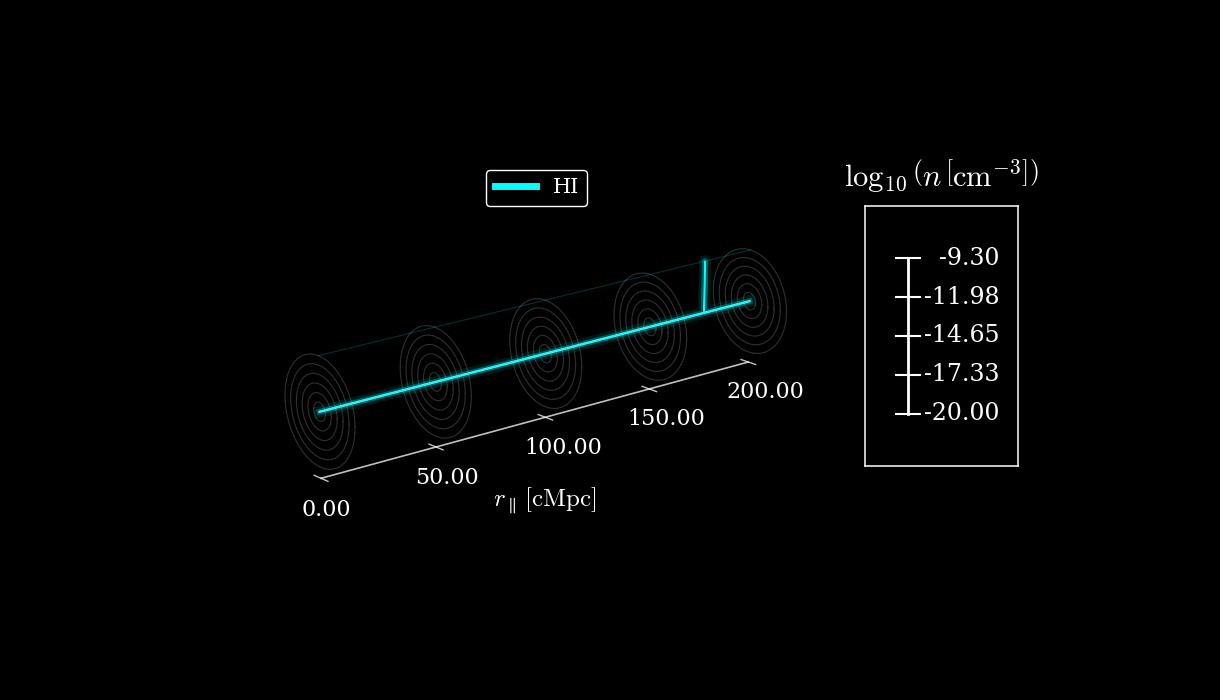

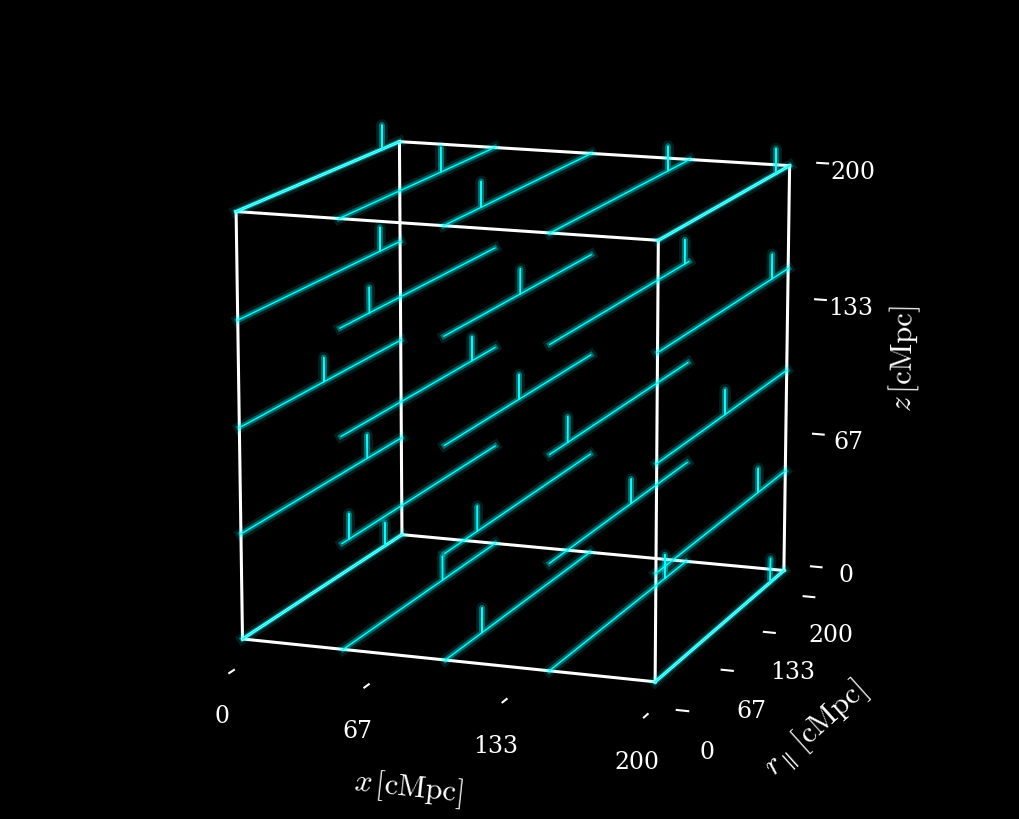

In [12]:
x_array = points[..., 1]

key_field_plot = 'number_density'
plot_dict = {}
for ii, key in enumerate(sampled_fields.keys()):
    plot_dict[key] = jnp.log10(sampled_fields[key][key_field_plot])

fig, ax = pt.plot_3d_radar_cylinder(
    x_array=x_array, y_dict=plot_dict, cylinder_radius=20.0, skewer_index=0, field_logscale=False,
    x_axis_label=r"$r_{\parallel}\,[{\rm cMpc}]$",
    field_units=r"$\log_{10}\left(n \, \left[\mathrm{cm}^{-3}\right] \right)$",
    n_samples_plot=1, n_y_slices=5, n_x_ticks=5, x_axis_pad=0.2, factor_ticks_z=15.0,
    factor_x_label=1.3, show_profile_points=False,
)

fig, ax = pt.plot_3d_neon_ridge_cube(
    points=points, y_dict=plot_dict, normalization="global", field_logscale=False, normalize_scales=False,
    x_label=r"$x\,[{\rm cMpc}]$", y_label=r"$r_{\parallel}\,[{\rm cMpc}]$", z_label=r"$z\,[{\rm cMpc}]$",
    axis_label_fontsize=22, x_label_pad = 25.0, y_label_pad = 25.0, z_label_pad = 25.0, n_axis_ticks=(4, 4, 4),
    ridge_scale=1.0,
)

# Optical depth

In [13]:
N_v = 15000

In [14]:
a_dagger = 1/(1+z_box)
a_em = skewer_bundle.scale_factors[0, 0, 0]
v_max = phys.c_kms * jnp.log(a_dagger / a_em)
velocities_kms = jnp.linspace(0, v_max, N_v)

tau = od.OpticalDepthCalculator(
    skewer_bundle=skewer_bundle, velocities_kms=velocities_kms, line_bundle=line_bundle, fields=fields, a_dagger=a_dagger, debug_memory=True,
)
tau.compute()
tau.wrap_to_ref_line()
optical_depth = tau.optical_depth

2026-05-28 11:02:28,161 - INFO - 
[OPTICAL_DEPTH][MEM] initialized
  Process RSS : 1.035 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   0.8%
  System RAM  : used=48.108 GB, available=77.499 GB  [███████████░░░░░░░░░░░░░░░░░]  38.3%
  Change      : ΔRSS=first checkpoint
2026-05-28 11:02:28,162 - INFO - [OPTICAL_DEPTH] start: ii_cosmology=0, voigt=ExoJAX
2026-05-28 11:02:28,163 - INFO - 
[OPTICAL_DEPTH][MEM] loaded quadri_vectors
  Process RSS : 1.039 / 125.607 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   0.8%
  System RAM  : used=48.112 GB, available=77.495 GB  [███████████░░░░░░░░░░░░░░░░░]  38.3%
  Change      : ΔRSS=+0.004 GB
  Array       : shape=(25, 5000, 4), dtype=float32, nbytes=0.002 GB  [░░░░░░░░░░░░░░░░░░░░░░░░░░░░]   0.0%
2026-05-28 11:02:59,259 - INFO - 
[OPTICAL_DEPTH][MEM] after compute_line_profiles
  Process RSS : 28.080 / 125.607 GB  [██████░░░░░░░░░░░░░░░░░░░░░░]  22.4%
  System RAM  : used=76.186 GB, available=49.421 GB  [█████████████████░░░░░░░░░░░]  60.7%
  Change      : 

### Plot optical depth

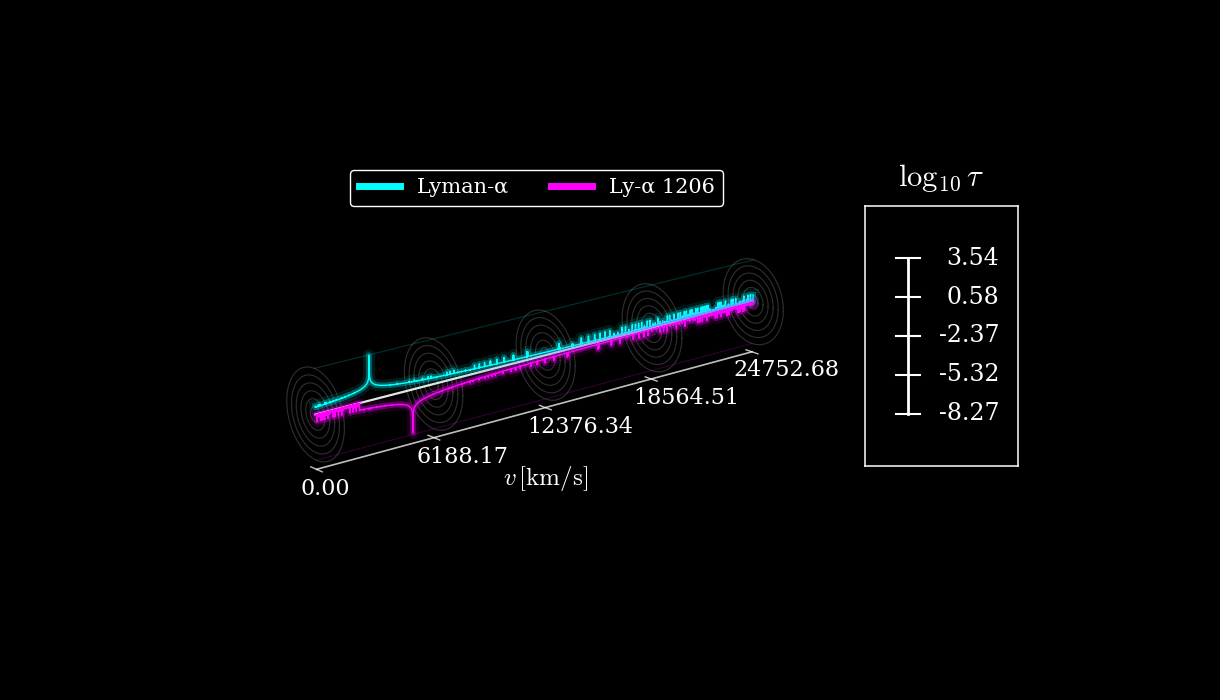

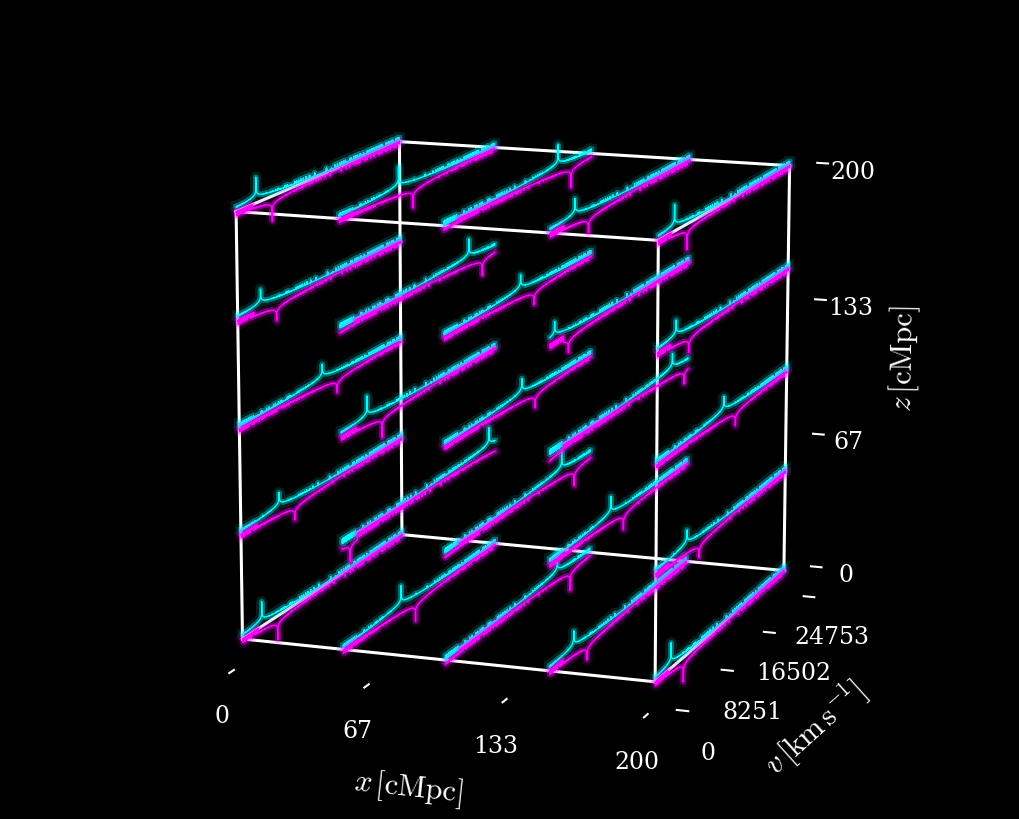

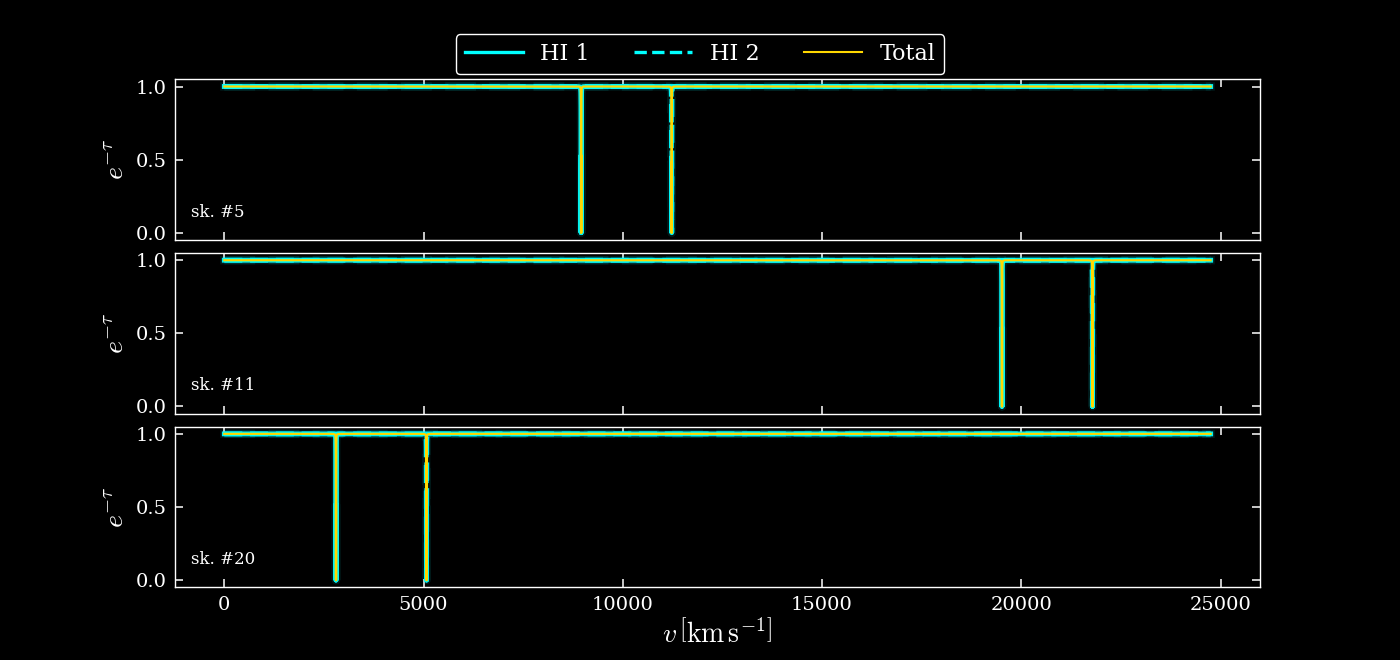

In [15]:
x_array = jnp.tile(velocities_kms[None], (tau.N_sk, 1))

plot_dict = {}
for ii, line in enumerate(line_bundle.lines):
    plot_dict[line.name] = jnp.log10(tau.optical_depth[ii])
    
fig, ax = pt.plot_3d_radar_cylinder(
    x_array=x_array, y_dict=plot_dict, cylinder_radius=2000.0, skewer_index=0, field_logscale=False,
    factor_ticks_x=3.0, factor_ticks_z=1200.0, factor_x_label=1.3, x_axis_label=r"$v\,[{\rm km / s}]$",
    field_units=r"$\log_{10}\tau$", n_samples_plot=1, n_y_slices=5, n_x_ticks=5, x_axis_pad=0.2,
    show_profile_points=False,
)

x_trans = points[:tau.N_sk, 0, 0]
z_trans = points[:tau.N_sk, 0, 2]

x_cube = jnp.tile(x_trans[:, None], (1, N_v))
y_cube = jnp.tile(velocities_kms[None, :], (tau.N_sk, 1))
z_cube = jnp.tile(z_trans[:, None], (1, N_v))

points_cube_velocities = jnp.stack([x_cube, y_cube, z_cube], axis=-1)

fig, ax = pt.plot_3d_neon_ridge_cube(
    points=points_cube_velocities, y_dict=plot_dict, normalization="global", field_logscale=False, normalize_scales=True,
    x_label=r"$x\,[{\rm cMpc}]$", y_label=r"$v\,[{\rm km\,s^{-1}}]$", z_label=r"$z\,[{\rm cMpc}]$", axis_label_fontsize=22,
    ridge_scale=1.0, x_label_pad = 25.0, y_label_pad = 25.0, z_label_pad = 25.0, n_axis_ticks=(4, 4, 4),
)

fig, axes, idx = pt.plot_transmission_samples_neon(
    F_over_F0=np.exp(-tau.optical_depth), line_bundle=line_bundle, x_axis_array=velocities_kms,
    x_label=r"$v \, \left[\mathrm{km} \, \mathrm{s}^{-1}\right]$", N_plot_sample=3, seed=137,
    line_lw=3.5, line_glow_lw=6.0, line_alpha=0.95,line_glow_alpha=0.1, line_legend_lw=2.4,
    total_color="gold", total_lw=1.5, total_glow_lw=2.0,
)

# Overflux

In [16]:
overflux = sjx.optical_depth.overflux.DeltaFieldBuilder(tau.optical_depth).build()

2026-05-28 11:03:14,383 - INFO - Initialized DeltaFieldBuilder with 2 lines, N_samples=25, N_points=15000.
2026-05-28 11:03:14,384 - INFO - Starting build().
2026-05-28 11:03:14,614 - INFO - Finished build(): N_samples=25, subset_keys=3, composite_keys=1.


In [17]:
delta_v_list = list(np.array(line_bundle.delta_v))
velocity_domain = np.max(tau.velocities_kms) - np.min(tau.velocities_kms)
dv = np.diff(tau.velocities_kms)[0]
stats = sjx.summary_stats.P1D_xi1D.OverfluxStatistics1D(overflux, dv)
ordered_pairs = stats.ordered_pairs

# $P 1D$

In [18]:
stats.compute_p1d()

Pk_total_from_terms = stats.Pk_total_from_terms

Pk_total_per_sample = stats.Pk_total_per_sample
Pk_total = stats.Pk_total

Pk_pair_per_sample = stats.Pk_pair_per_sample
Pk_pair = stats.Pk_pair

k = stats.k

Angular wavenumber: $k_m = 2\pi f_m = \frac{2\pi m}{N_v dv}$

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:633: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


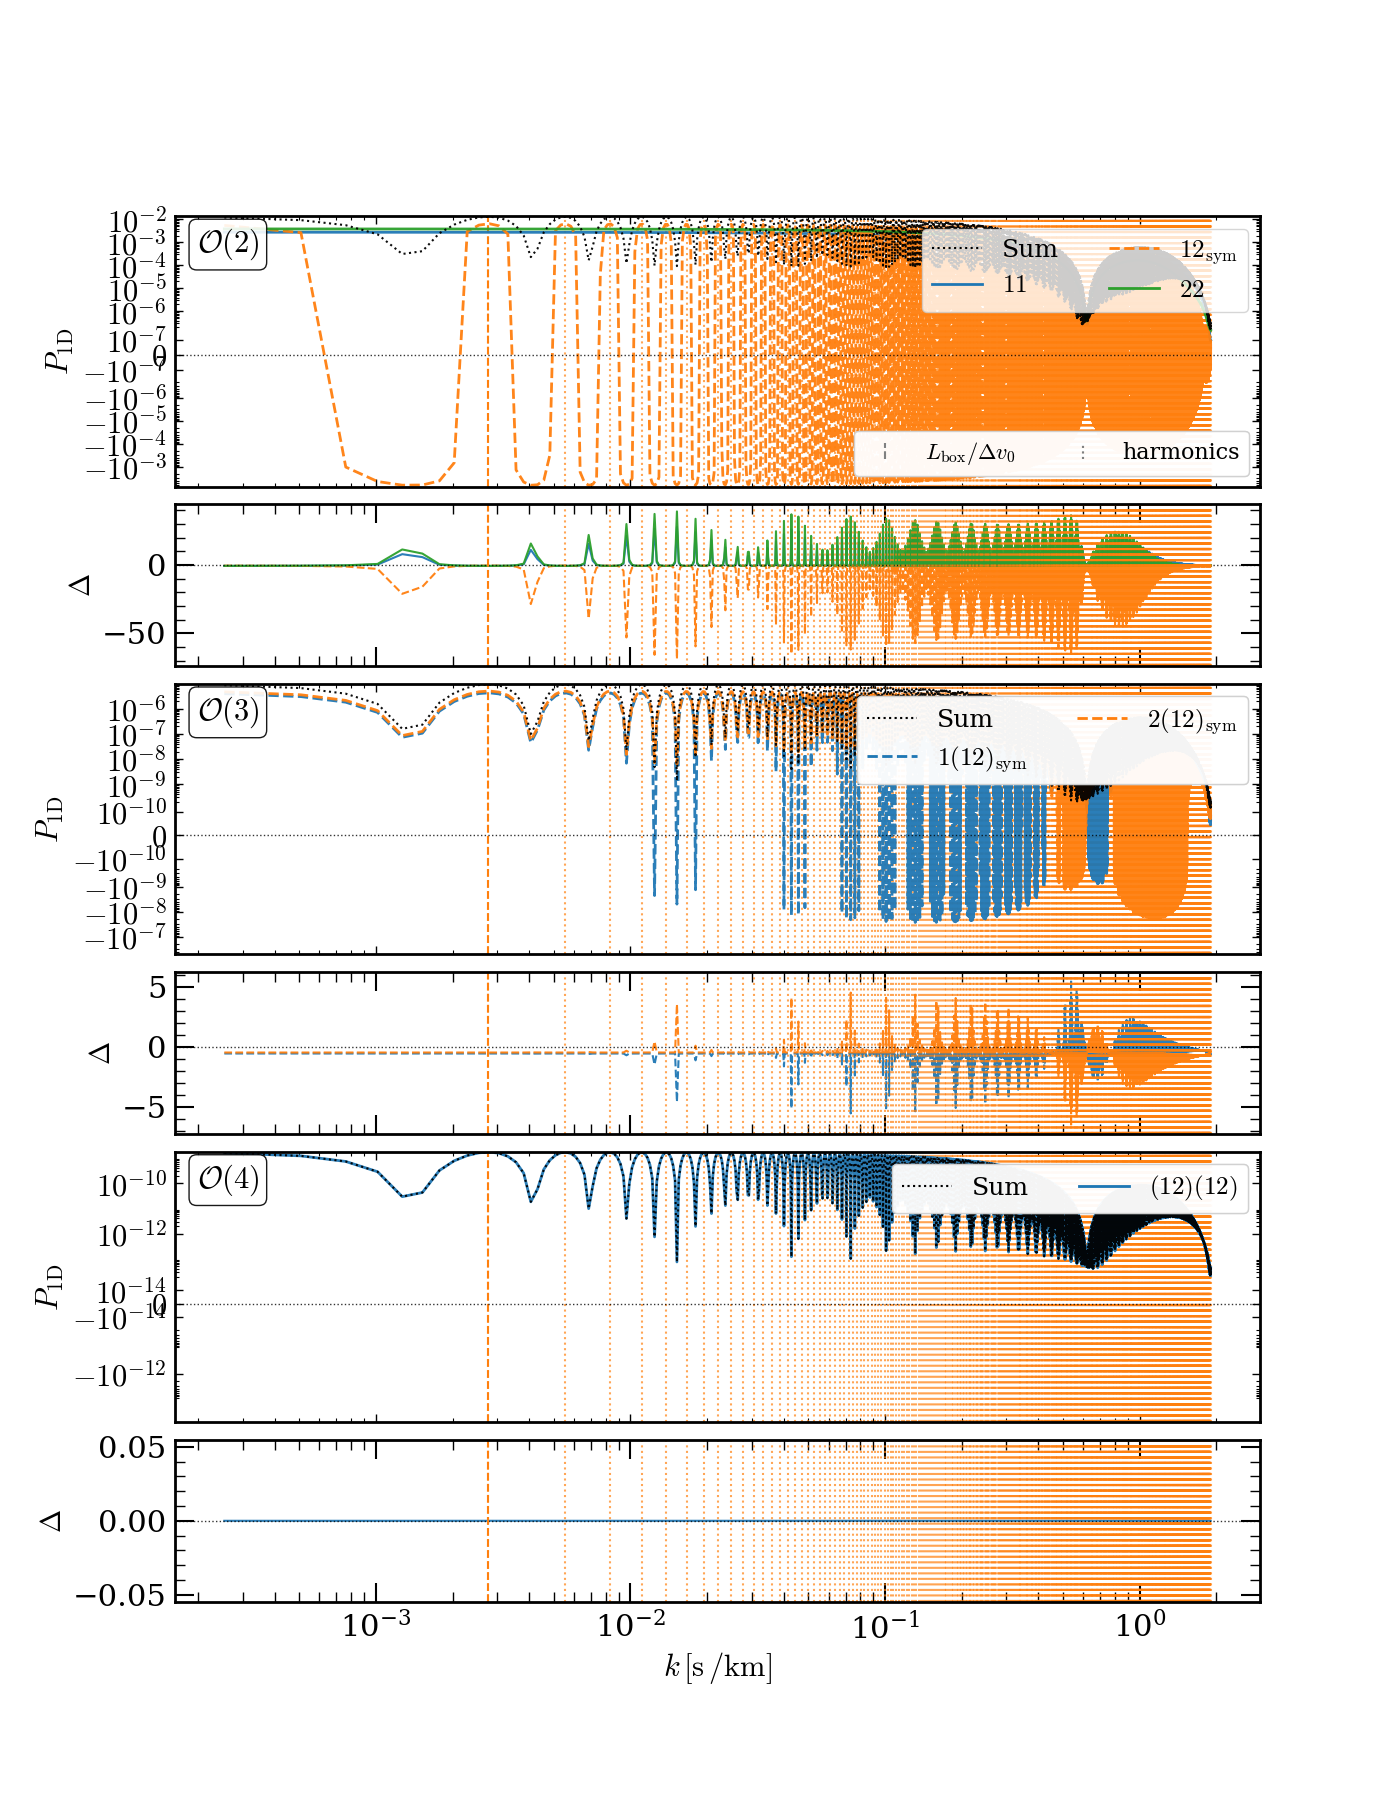

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:784: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


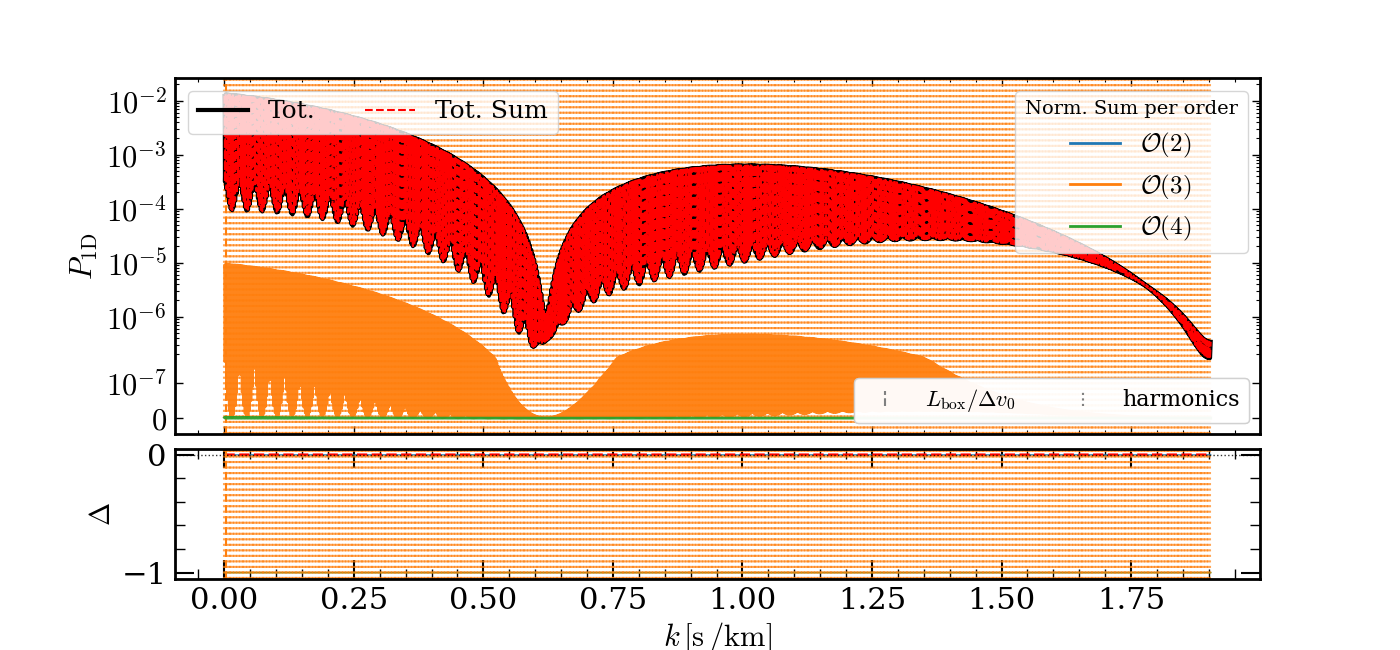

In [19]:
# ================================================================
# Plot P1D

fig, axes, axes_res, order_sum_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_p1d_by_order(
    ordered_pairs=ordered_pairs, Pk_pair=Pk_pair, k=k, delta_v_list=delta_v_list, L_box=velocity_domain, Npix=N_v,
    tolerance_threshold=1e-6, use_log_x=True, # xlim=(2.0, 600),
    residual_mode="sum", show_harmonics=True, use_symlog_main=True, use_symlog_residual=False,
    symlog_linscale=1.0, symlog_label_minor=False, symlog_sci_cutoff=1e-2, legend_ncol_terms=2,
    xlabel=r"$k\,[{\rm s\,/km}]$", ylabel=r"$P_{\rm 1D}$", residual_ylabel=r"$\Delta$",
)

fig, (ax, ax_res), order_sum_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_p1d_total_recovery(
    Pk_total=Pk_total, Pk_total_from_terms=Pk_total_from_terms, Pk_pair=Pk_pair, k=k, delta_v_list=delta_v_list, L_box=velocity_domain, Npix=N_v,
    ordered_pairs=ordered_pairs, show_harmonics=True, show_order_sums=True, show_order_sum_residuals=True,
    use_symlog_main=True, use_symlog_residual=False, xlabel=r"$k\,[{\rm s\,/km}]$"
)

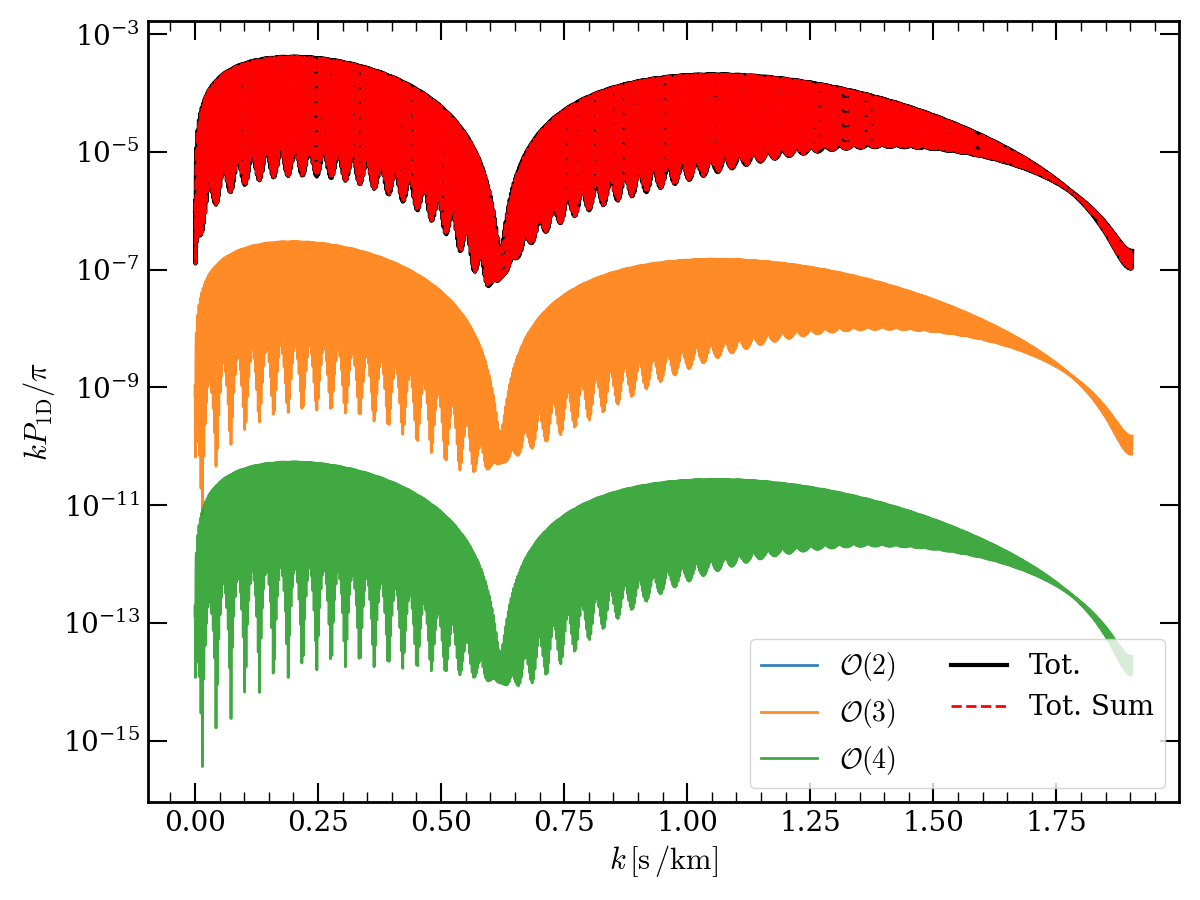

In [20]:
# ===============================================================
# Build order sums from Pk_pair

ordered_pairs = list(Pk_pair.keys()) if ordered_pairs is None else ordered_pairs
order_sum_dict = {}
for pair in ordered_pairs:
    A, B = pair
    order = len(A) + len(B)
    if order not in order_sum_dict:
        order_sum_dict[order] = np.zeros_like(Pk_pair[pair], dtype=float)
    order_sum_dict[order] += Pk_pair[pair].real
orders = sorted(order_sum_dict.keys())

# ===============================================================
# Plot P1D

cmap = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(12, 9))
for i, order in enumerate(orders):
    y_order = order_sum_dict[order][1:] * k[1:] / np.pi
    ax.plot(k[1:], y_order, lw=2.0, color=cmap(i % 10), alpha=0.9, label=rf"$\mathcal{{O}}({order})$")

# Total
ax.plot(k[1:], Pk_total.real[1:] * k[1:] / np.pi, lw=3.0, color="k", label=r"Tot.")

# Total recovered from terms
ax.plot(k[1:], Pk_total_from_terms.real[1:] * k[1:] / np.pi, lw=2.0, color="red", ls="--", label=r"Tot. Sum")

ax.set_yscale("log")

ax.set_xlabel(r"$k\,[{\rm s\,/km}]$", fontsize=22)
ax.set_ylabel(r"$k P_{\rm 1D} / \pi$", fontsize=22)

# ax.set_xlim([0.0, 0.045])
# ax.set_ylim([0.007, 0.6])

ax.tick_params(axis="both", labelsize=20)
ax.legend(fontsize=20, ncol=2)

plt.tight_layout()
plt.show()

# $\xi 1D$

In [21]:
stats.compute_xi1d()

xi_total_from_terms = stats.xi_total_from_terms

xi_total_per_sample = stats.xi_total_per_sample
xi_total = stats.xi_total

xi_pair_per_sample = stats.xi_pair_per_sample
xi_pair = stats.xi_pair

lags = stats.lags

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:978: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


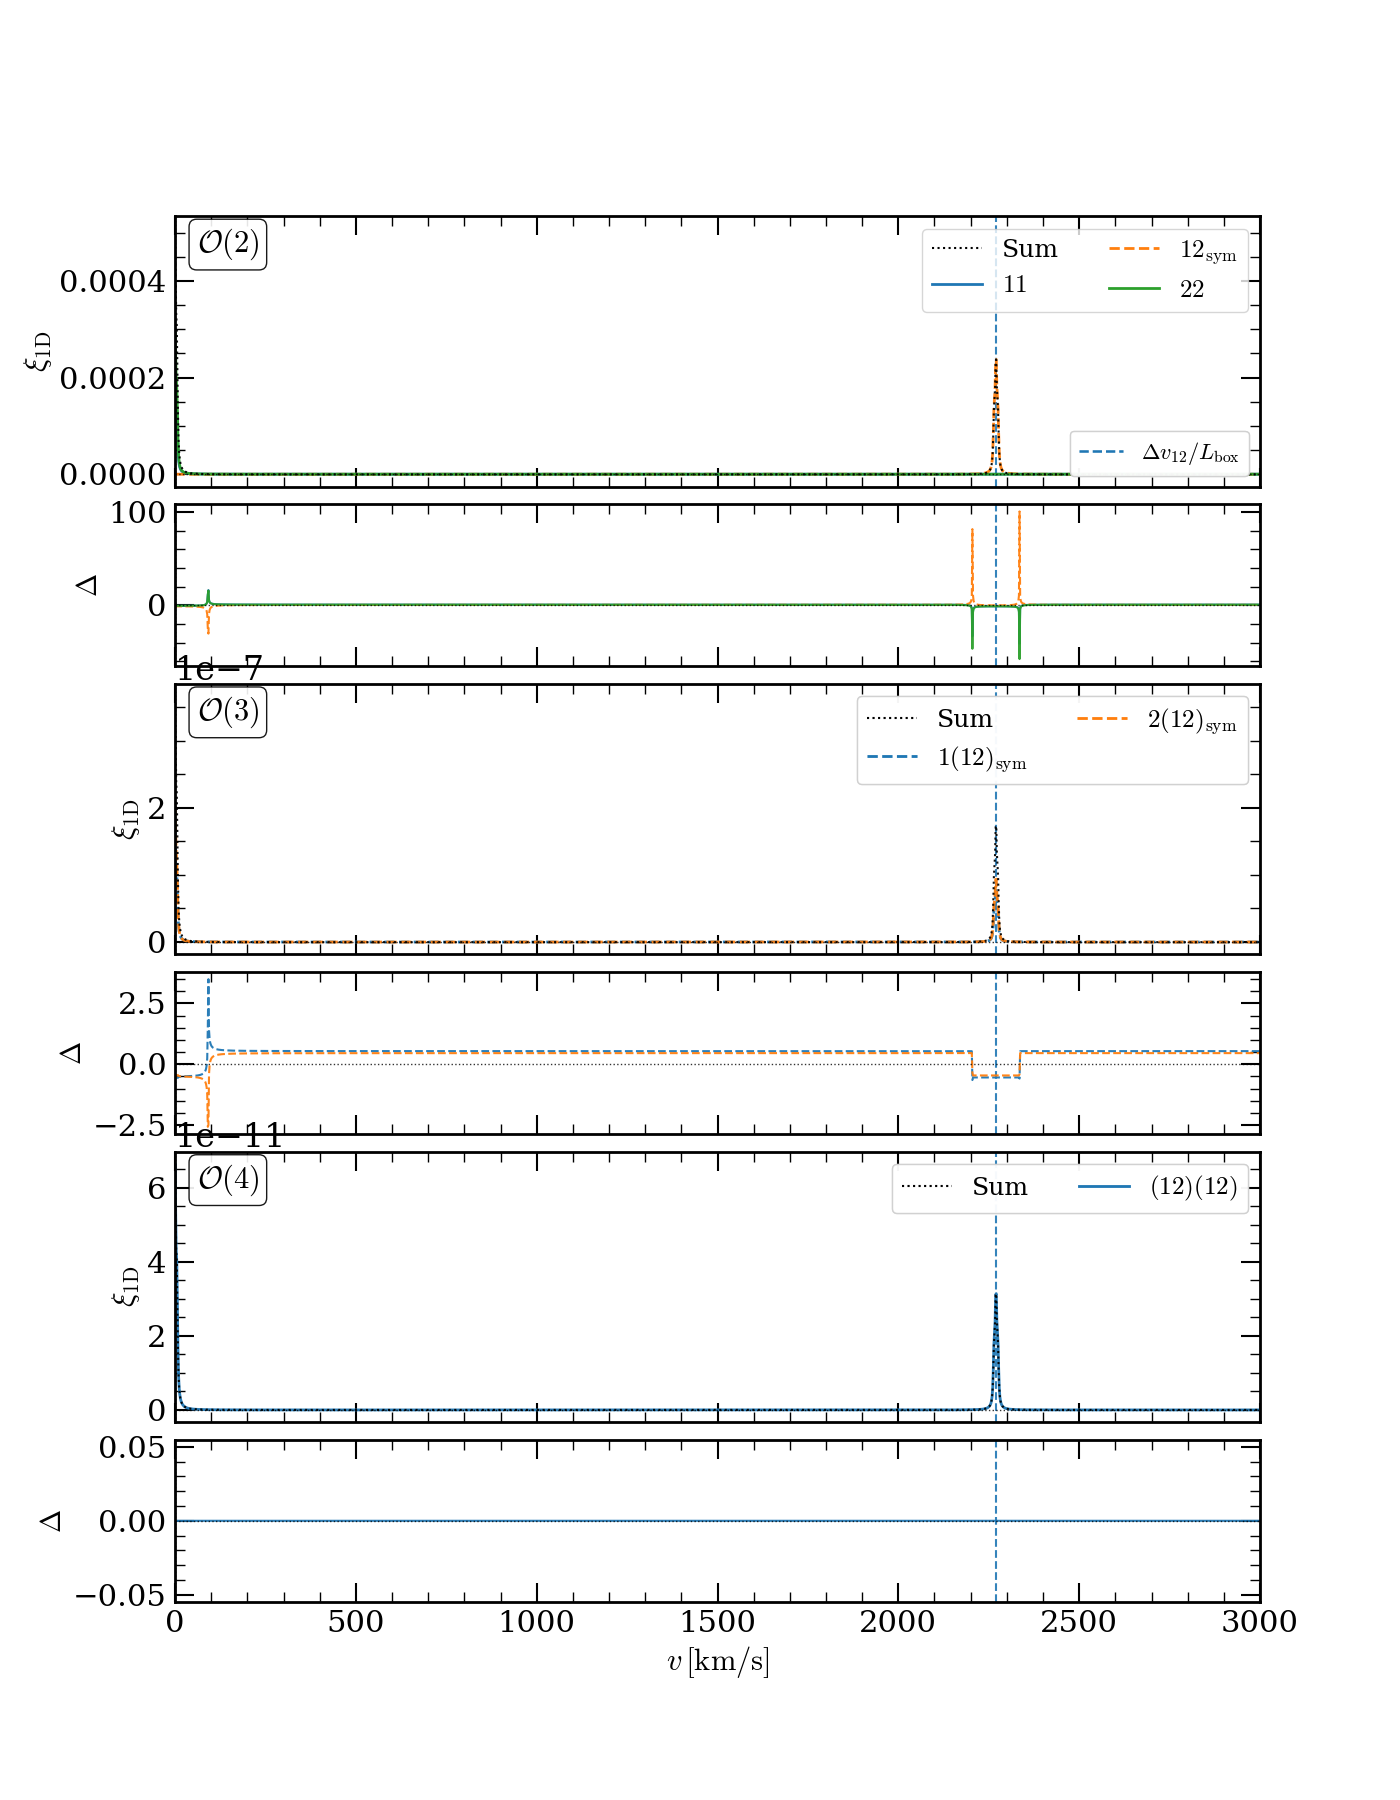

/home/dlopez/Documentos/0.profesional/Postdoc/USP/Projects/SkewerJAX/skewerjax/utils/plotting_tools_P1D_xi1D.py:1137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


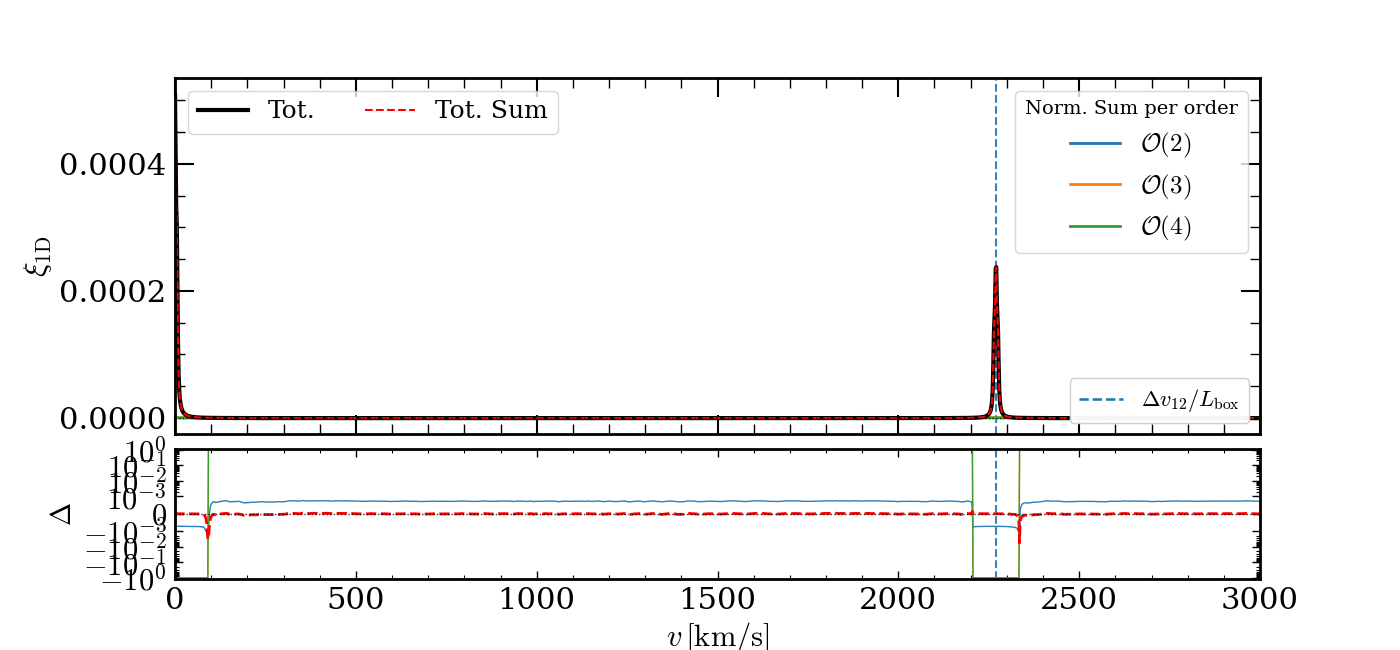

In [22]:
fig, axes, axes_res, xi_order_sum_dict, xi_order_sum_plot_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_xi_by_order(
    ordered_pairs=ordered_pairs, xi_pair=xi_pair, lags=lags, delta_v_list=delta_v_list, L_box=velocity_domain,
    tolerance_threshold=1e-6, residual_mode="sum", show_delta_v_diff_lines=True, use_symlog_main=False,
    use_symlog_residual=False, symlog_linscale=1.0, symlog_base=10, symlog_label_minor=False, symlog_sci_cutoff=1e-2,
    show_order_badge=True, legend_ncol_terms=2, xlabel=r"$v\,\left[{\rm km / s}\right]$", ylabel=r"$\xi_{\rm 1D}$", residual_ylabel=r"$\Delta$",
    xlim=(-0.0, 3000), # xlim=(-0.0, v_max/2)
)

fig, (ax, ax_res), xi_order_sum_dict, xi_order_sum_plot_dict = sjx.utils.plotting_tools_P1D_xi1D.plot_xi_total_recovery(
    xi_total=xi_total, xi_total_from_terms=xi_total_from_terms, xi_pair=xi_pair, lags=lags, delta_v_list=delta_v_list, L_box=velocity_domain, ordered_pairs=ordered_pairs,
    show_order_sums=True, show_order_sum_residuals=True, show_delta_v_diff_lines=True, annotate_half_line=False,
    half_line_text=r"$L_\mathrm{box}/2$", use_symlog_main=False, use_symlog_residual=True, main_symlog_linthresh=None,
    symlog_linscale=1.0, symlog_base=10, symlog_sci_cutoff=1e-2, xlabel=r"$v\,\left[{\rm km / s}\right]$", ylabel=r"$\xi_{\rm 1D}$", residual_ylabel=r"$\Delta$",
    xlim=(-0.0, 3000), # xlim=(-0.0, v_max/2)
)

# Models

In [23]:
from scipy.optimize import minimize, minimize_scalar
from jax.numpy.fft import rfft, rfftfreq
import skewerjax.models.models as models

In [24]:
# ------------------------------------------------------------
# 1. Inputs from your notebook
overflux_lya = overflux.delta_terms["1"]  # shape (N_skewer, N_v)

# Build McDonald basis using amplitude = 1. Then the fitted model is: delta_total(A) = delta_Lya + A * delta_shifted_metal_basis
overflux_mcdonald_basis = models.build_mcdonald_overflux_fields(
    overflux_lya=overflux_lya, velocities_kms=velocities_kms, line_bundle=line_bundle, amplitudes=jnp.array([1.0]),
)
delta_lya = overflux_mcdonald_basis[0]          # (N_skewer, N_v)
delta_metal_basis = overflux_mcdonald_basis[1]  # (N_skewer, N_v), shifted Lyα with A=1

# ------------------------------------------------------------
# 2. Compute P(k; A) efficiently
k_mcdonald = 2.0 * jnp.pi * rfftfreq(N_v, d=dv)
prefactor = dv / N_v

F_lya = rfft(delta_lya, axis=1)
F_metal = rfft(delta_metal_basis, axis=1)

# P(A) = P00 + 2 A P01 + A^2 P11
P00_per_sample = (prefactor * F_lya * jnp.conjugate(F_lya)).real
P11_per_sample = (prefactor * F_metal * jnp.conjugate(F_metal)).real
P01_per_sample = (prefactor * F_lya * jnp.conjugate(F_metal)).real

P00 = jnp.mean(P00_per_sample, axis=0)
P11 = jnp.mean(P11_per_sample, axis=0)
P01 = jnp.mean(P01_per_sample, axis=0)

Pk_target = jnp.asarray(Pk_total).real

def Pk_mcdonald_from_A(A):
    """
    McDonald model P1D for one metal amplitude A.
    """
    return P00 + 2.0 * A * P01 + A**2 * P11

# ------------------------------------------------------------
# 3. Fit A
# Exclude k=0 and optionally restrict k range. Adjust k_fit_max if you want to fit only the large-scale oscillatory regime.
k_fit_min = 0.0
k_fit_max = float(k_mcdonald[-1])

fit_mask = ((k_mcdonald > k_fit_min) & (k_mcdonald <= k_fit_max) & jnp.isfinite(Pk_target) & (Pk_target > 0.0))

def loss_A(A):
    P_model = Pk_mcdonald_from_A(A)
    P_model_fit = np.asarray(P_model[fit_mask])
    P_target_fit = np.asarray(Pk_target[fit_mask])
    
    residual = np.log(P_model_fit) - np.log(P_target_fit) # loss type
    # residual = (np.log(P_model_fit) - np.log(P_target_fit)) / np.log(P_target_fit)

    return float(np.mean(residual**2))

# Use a broad bracket. Expand if needed.
fit_result = minimize_scalar(loss_A, bounds=(-1.0, 1.0), method="bounded", options={"xatol": 1e-10})

A_best = fit_result.x
Pk_total_mcdonald_best = Pk_mcdonald_from_A(A_best)

print(f"Best-fit McDonald amplitude A = {A_best:.8f}")
print(f"Final loss = {fit_result.fun:.6e}")
print(f"Optimizer success = {fit_result.success}")
print(f"Optimizer message = {fit_result.message}")

Best-fit McDonald amplitude A = 0.87177431
Final loss = 2.279978e-01
Optimizer success = True
Optimizer message = Solution found.


In [26]:
# ------------------------------------------------------------
# 1. Inputs from your notebook
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from jax.numpy.fft import rfft, rfftfreq

overflux_lya = overflux.delta_terms["1"]  # shape (N_skewer, N_v)

k_ma = 2.0 * jnp.pi * rfftfreq(N_v, d=dv)
prefactor = dv / N_v

F_lya = rfft(overflux_lya, axis=1)
P00_per_sample = (prefactor * F_lya * jnp.conjugate(F_lya)).real
P00 = jnp.mean(P00_per_sample, axis=0)  # Lyalpha-only P1D

Pk_target = jnp.asarray(Pk_total).real

assert Pk_target.shape == P00.shape, (
    f"Pk_target shape {Pk_target.shape} does not match P00 shape {P00.shape}."
)

# For current toy case: one non-Lyalpha line, SiIII.
assert len(line_bundle.delta_v) - 1 == 1, (
    "This compact Ma block assumes one non-Lyalpha line, SiIII."
)

delta_v_siIII = abs(float(line_bundle.delta_v[1]))

In [27]:
# ------------------------------------------------------------
# 2. Ma et al. Section 3.2 model
# theta = [a_auto, k_auto, a_cross, k_cross]
#
# P_Ma(k) =
#   P_Lya(k)
#   + a_auto exp(k/k_auto) P_Lya(k)
#   + a_cross cos(Delta_v k) exp(k/k_cross) P_Lya(k)

def Pk_ma_from_theta(theta):
    a_auto, k_auto, a_cross, k_cross = theta

    ratio_auto = a_auto * jnp.exp(k_ma / k_auto)
    ratio_cross = a_cross * jnp.cos(delta_v_siIII * k_ma) * jnp.exp(k_ma / k_cross)

    return P00 * (1.0 + ratio_auto + ratio_cross)


def Pk_ma_components_from_theta(theta):
    a_auto, k_auto, a_cross, k_cross = theta

    P_auto = a_auto * jnp.exp(k_ma / k_auto) * P00
    P_cross = a_cross * jnp.cos(delta_v_siIII * k_ma) * jnp.exp(k_ma / k_cross) * P00
    P_total = P00 + P_auto + P_cross

    return P_total, P_auto, P_cross

In [28]:
# ------------------------------------------------------------
# 3. Fit theta = [a_auto, k_auto, a_cross, k_cross]
#
# Ma et al. validate their model for k < 0.2 s/km.
# For your toy low-k plot, you can reduce k_fit_max if desired.

k_fit_min = 0.0
k_fit_max = min(0.2, float(k_ma[-1]))

fit_mask = (
    (k_ma > k_fit_min)
    & (k_ma <= k_fit_max)
    & jnp.isfinite(Pk_target)
    & jnp.isfinite(P00)
    & (Pk_target > 0.0)
    & (P00 > 0.0)
)

fit_mask_np = np.asarray(fit_mask)

def loss_theta(theta):
    P_model = np.asarray(Pk_ma_from_theta(theta))
    P_truth = np.asarray(Pk_target)

    P_model_fit = P_model[fit_mask_np]
    P_truth_fit = P_truth[fit_mask_np]

    if np.any(~np.isfinite(P_model_fit)) or np.any(P_model_fit <= 0.0):
        return np.inf

    residual = np.log(P_model_fit) - np.log(P_truth_fit)
    return float(np.mean(residual**2))


# Initial guess close to the Ma z~3 fiducial shape, but not fixed to it.
theta0 = np.array([
    3.0e-3,    # a_auto
    4.0e-2,    # k_auto > 0
    3.0e-2,    # a_cross
   -2.0e-2,    # k_cross < 0
])

# Broad toy-friendly bounds.
# For a stricter physical fit, set a_cross lower bound to 0.
bounds = [
    (0.0, 50.0),      # a_auto
    (1.0e-3, 0.5),    # k_auto > 0
    (-50.0, 50.0),    # a_cross; allow sign in case of convention mismatch
    (-0.5, -1.0e-3),  # k_cross < 0
]

fit_result_ma = minimize(
    loss_theta,
    theta0,
    method="Powell",
    bounds=bounds,
    options={
        "maxiter": 5000,
        "xtol": 1e-10,
        "ftol": 1e-12,
    },
)

theta_best_ma = fit_result_ma.x
Pk_total_ma_best, Pk_auto_ma_best, Pk_cross_ma_best = Pk_ma_components_from_theta(theta_best_ma)

a_auto_best, k_auto_best, a_cross_best, k_cross_best = theta_best_ma

print("Best-fit Ma et al. parameters:")
print(f"a_auto  = {a_auto_best:.8e}")
print(f"k_auto  = {k_auto_best:.8e} [s/km]")
print(f"a_cross = {a_cross_best:.8e}")
print(f"k_cross = {k_cross_best:.8e} [s/km]")
print(f"Final loss = {fit_result_ma.fun:.6e}")
print(f"Optimizer success = {fit_result_ma.success}")
print(f"Optimizer message = {fit_result_ma.message}")

Best-fit Ma et al. parameters:
a_auto  = 7.67104041e-03
k_auto  = 4.13374595e-02 [s/km]
a_cross = 4.99999989e+01
k_cross = -1.00000051e-03 [s/km]
Final loss = inf
Optimizer success = True
Optimizer message = Optimization terminated successfully.


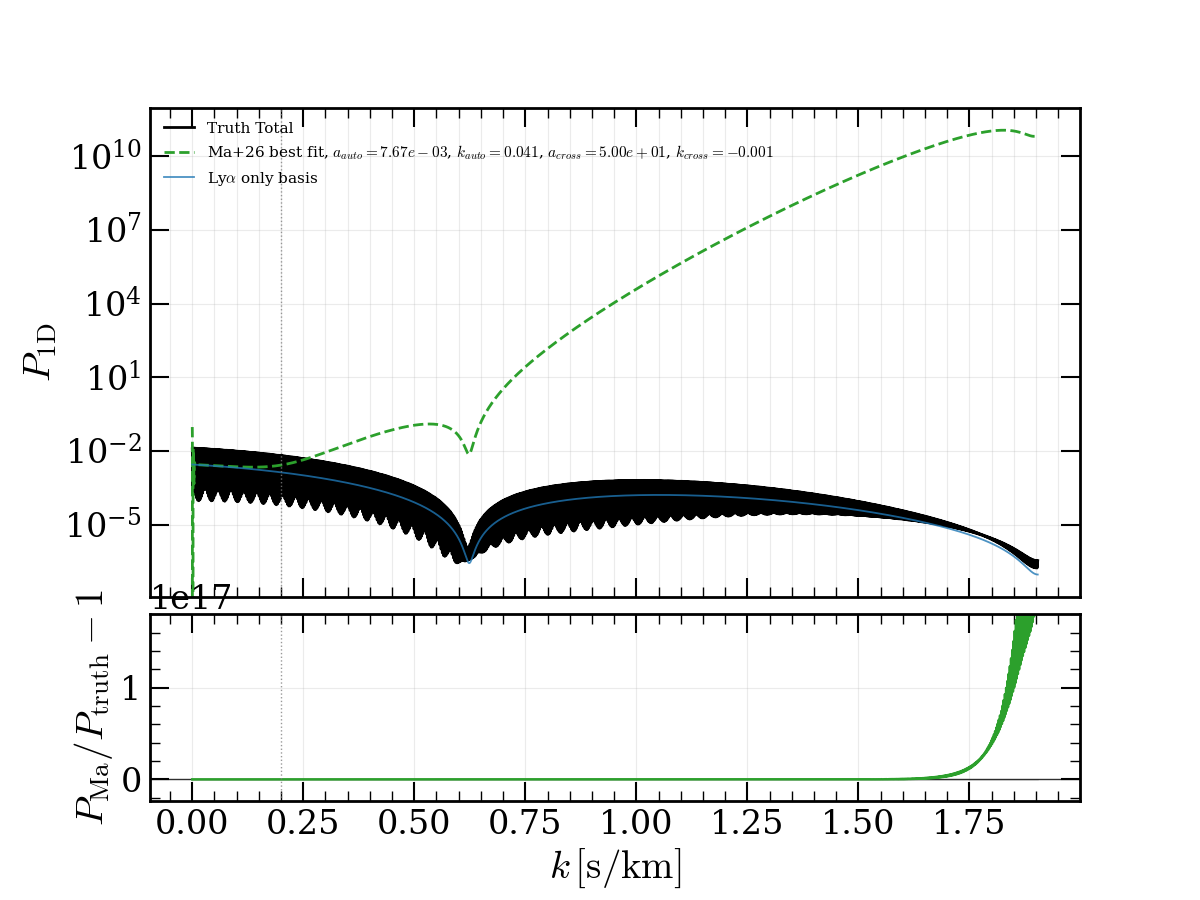

In [29]:
# ------------------------------------------------------------
# 4. Improved visualization

k_np = np.asarray(k_ma)
Pk_target_np = np.asarray(Pk_target)
Pk_model_np = np.asarray(Pk_total_ma_best)
P00_np = np.asarray(P00)

ratio = Pk_model_np / Pk_target_np
frac_residual = ratio - 1.0

plot_mask = k_np > 0.0

fig, (ax, ax_res) = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [3.0, 1.15], "hspace": 0.05},
)

# Main P1D panel
ax.plot(
    k_np[plot_mask],
    Pk_target_np[plot_mask],
    color="black",
    lw=2.0,
    label="Truth Total",
)

ax.plot(
    k_np[plot_mask],
    Pk_model_np[plot_mask],
    color="tab:green",
    lw=2.0,
    ls="--",
    label=(
        r"Ma+26 best fit, "
        rf"$a_{{auto}}={a_auto_best:.2e}$, "
        rf"$k_{{auto}}={k_auto_best:.3f}$, "
        rf"$a_{{cross}}={a_cross_best:.2e}$, "
        rf"$k_{{cross}}={k_cross_best:.3f}$"
    ),
)

ax.plot(
    k_np[plot_mask],
    P00_np[plot_mask],
    color="tab:blue",
    lw=1.3,
    alpha=0.8,
    label=r"Ly$\alpha$ only basis",
)

ax.axvline(k_fit_max, color="gray", lw=1.0, ls=":", alpha=0.8)

ax.set_yscale("log")
ax.set_ylabel(r"$P_{\rm 1D}$")
ax.legend(frameon=False, fontsize=11)
ax.grid(True, which="both", alpha=0.25)

# Residual panel
ax_res.axhline(0.0, color="black", lw=1.0, alpha=0.8)

ax_res.plot(
    k_np[plot_mask],
    frac_residual[plot_mask],
    color="tab:green",
    lw=1.8,
)

ax_res.fill_between(
    k_np[plot_mask],
    -0.05,
    0.05,
    color="gray",
    alpha=0.18,
    label=r"$\pm 5\%$",
)

ax_res.axvline(k_fit_max, color="gray", lw=1.0, ls=":", alpha=0.8)

ax_res.set_xlabel(r"$k\,[{\rm s/km}]$")
ax_res.set_ylabel(r"$P_{\rm Ma}/P_{\rm truth}-1$")
ax_res.grid(True, alpha=0.25)

finite_res = frac_residual[plot_mask & np.isfinite(frac_residual)]
if finite_res.size > 0:
    qlo, qhi = np.nanpercentile(finite_res, [2, 98])
    pad = 0.15 * max(abs(qlo), abs(qhi), 1e-3)
    ax_res.set_ylim(qlo - pad, qhi + pad)

plt.show()